## SD-CPIT vs complete CPIT model for zuck_small (MineLib)

The instance follows the official MineLib file `zuck_small.cpit`: 20 periods, discount rate 0.10, mining (rock tonnage, at most 60,000,000 t per period) and processing (ore tonnage, at most 20,000,000 t per period).

Reference values for this instance:

| Value | NPV |
|---|---|
| CPIT LP upper bound (MineLib) | 854,182,396 |
| Best-known solution | 848,112,016 (Samavati et al., 2018) |
| SD-CPIT (Table 2 of the article) | 847,050,785 |

The cells are those of `zuck_small.ipynb` and of the newman1 comparison notebook (`01_newman1/newman1_sdcpit_vs_cpit_gurobi`). The changes, marked `# added` in the code, are:

1. Gurobi log file for each solution (`set_gurobi_log`).
2. Complete multi-period model: LP relaxation and integer model, each with a time limit of 3,600 s; the integer model uses the default relative MIP gap (1e-4) and reports the best solution, the bound, and the final MIP gap.
3. Progress messages while the precedence constraints of the complete model are built.
4. Storage of results after each solution for the final comparison.

| Solution | Gurobi log |
|---|---|
| SD-CPIT | zuck_small_gurobi_sdcpit.log |
| CPIT LP relaxation (UB) | zuck_small_gurobi_cpit_relaxed.log |
| CPIT integer, time limit 3,600 s | zuck_small_gurobi_cpit_gap1e-4.log |

### Installing packages

In [1]:
!pip install -q pandas==3.0.2 numpy==2.4.4 mip==2.0.0 highspy==1.15.1 highsbox==1.15.1 gurobipy==13.0.1 matplotlib==3.10.8 plotly==6.6.0

In [2]:
import os, time, pandas as pd, gurobipy as gp, plotly.express as px, matplotlib.pyplot as plt, numpy as np
from mip import *

### Gurobi log and comparison helpers

In [3]:
# added: Gurobi log through Python-MIP and storage of results for the final comparison
# Python-MIP has no setter for Gurobi string parameters (LogFile), so the parameter is set directly
# in the Gurobi library already loaded by Python-MIP, on the environment of the model.
# The models themselves are not changed.
import weakref

_log_models = {}   # log file -> weak references to the models writing to it


def _set_gurobi_str_param(model, name, value):
    # Set a Gurobi string parameter on the environment of a Python-MIP model
    from mip.gurobi import ffi, grblib, GRBgetenv
    ffi.cdef("int GRBsetstrparam(GRBenv *env, const char *paramname, const char *value);", override=True)
    return grblib.GRBsetstrparam(GRBgetenv(model.solver._model), name.encode("utf-8"), value.encode("utf-8"))


def set_gurobi_log(model, log_file):
    # Write the Gurobi log of `model` to `log_file` (Gurobi appends to an existing file)
    if solver_name != "GRB":
        return
    model.verbose = 1   # OutputFlag = 1, required for Gurobi to write the log
    path = os.path.abspath(log_file)
    err = _set_gurobi_str_param(model, "LogFile", path)
    if err != 0:
        raise RuntimeError(f"Gurobi error {err} while setting LogFile = {log_file}")
    _log_models.setdefault(path, []).append(weakref.ref(model))


def new_log(log_file):
    # Remove the log of a previous run (each file keeps only the last run).
    # Models from a previous run that are still in memory keep the file open, and Windows cannot
    # delete an open file, so their log is closed first (LogFile = "").
    path = os.path.abspath(log_file)
    for ref in _log_models.pop(path, []):
        m = ref()
        if m is not None:
            try:
                _set_gurobi_str_param(m, "LogFile", "")
            except Exception:
                pass
    if os.path.exists(path):
        try:
            os.remove(path)
        except PermissionError:
            print(f"Warning: {log_file} is open in another process; the new log will be appended to it")


def store_full(log_file, relax):
    # Read the results left in memory by the full model cell (model, x, status, opt_time)
    ok = status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE)
    disc = ([sum(v[b] * (x[b][t].x or 0.0) for b in range(n_blocks)) / (1 + alpha) ** t for t in range(max_period)]
            if ok else [np.nan] * max_period)
    return {"npv": model.objective_value if ok else np.nan,
            "bound": (model.objective_value if relax else model.objective_bound) if ok else np.nan,
            "mip_gap": 0.0 if relax else (model.gap if ok else np.nan),
            "discounted": disc, "opt_time": opt_time, "status": status.name, "log": log_file}

### Loading block model file

In [4]:
# Load block model 
cols = ["id", "x", "y", "z", "cost", "value", "rock_tonnes", "ore_tonnes"]

# Read the block model (space-separated format)
blocks = pd.read_csv("zuck_small.blocks", sep=r"\s+", header=None, names=cols, engine="python")

# Calculating block value 
blocks['blockvalue'] = blocks['value'] - blocks['cost']

# Add a column to store the extraction period (initially empty)
blocks["period"] = pd.NA

print(f"Loaded {len(blocks):,} blocks")

Loaded 9,400 blocks


### Loading block precedences file

In [5]:
# Load precedence relations (Precedence file format: block_id  n_prec  prec1  prec2  ... )
precedence = {}
with open("zuck_small.prec") as f:
    for line in f:
        parts = line.strip().split()
        block_id = int(parts[0])
        n_prec = int(parts[1])
        precedence[block_id] = [int(parts[k]) for k in range(2, 2+n_prec)]

print(f"Loaded {sum(len(precs) for precs in precedence.values()):,} precedences")

Loaded 145,640 precedences


### Sequential Algorithm for Open-Pit Mine Scheduling

In [6]:
# Parameters 
max_period = 20     # Maximum number of scheduling periods
MC = 60_000_000     # Maximum Mine Capacity (tons)
PC = 20_000_000     # Maximum Process Capacity (tons), MineLib zuck_small.cpit
alpha = 0.10        # Discount rate for Net Present Value (NPV)

# Sequential Optimization 
code_start = time.time()
period_profit = []   # Store discounted values per period
extracted = set()    # Keep track of already extracted blocks
period_time = []     # added: optimization time per period (s), for the comparison
new_log("zuck_small_gurobi_sdcpit.log")  # added: Gurobi log (all periods appended to the same file)

# Build a model using Gurobi Solver, if available, or use open-source CBC solver (MIP Package Default)
try:
    Model(sense=MAXIMIZE, solver_name="GRB").clear()
    solver_name = "GRB"
except Exception:
    try:
        Model(sense=MAXIMIZE, solver_name="HIGHS").clear()   # HiGHS when no Gurobi license is active
        solver_name = "HIGHS"
    except Exception:
        solver_name = "CBC"
print(f"Using {solver_name} solver")
print("Starting optimization")

# Loop over scheduling periods
for t in range(max_period):

    # Available blocks = those not extracted yet
    B = list(blocks.index[~blocks["id"].isin(extracted)])
    if not B:
        break  # Stop if no available blocks remain

    # Extract data for available blocks
    ids = blocks.loc[B, "id"].tolist()
    v = blocks.loc[B, "blockvalue"].tolist()
    rock = blocks.loc[B, "rock_tonnes"].tolist()
    ore = blocks.loc[B, "ore_tonnes"].tolist()

    model = Model(sense=MAXIMIZE, solver_name=solver_name)
    model.max_seconds = 600  # 10 minutes
    model.max_mip_gap = 1e-4 # added: relative MIP gap
    set_gurobi_log(model, "zuck_small_gurobi_sdcpit.log")  # added: Gurobi log

    # Decision variables: x[b] = 1 if block b is extracted in this period
    x = [model.add_var(var_type=BINARY) for _ in B]

    # Objective: maximize undiscounted profit in this period
    model.objective = xsum(x[b] * v[b] for b in range(len(B)))

    # Precedence constraints: a block can only be extracted if its predecessors are extracted
    id_to_var = {ids[b]: b for b in range(len(B))}
    for bid in ids:
        if bid in precedence:
            for prec in precedence[bid]:
                if prec in extracted:
                    continue  # Already extracted in earlier period
                elif prec in id_to_var:
                    model += x[id_to_var[bid]] <= x[id_to_var[prec]]
                else:
                    # Predecessor not extracted yet → force this block = 0
                    model += x[id_to_var[bid]] == 0

    # Capacity constraint (only processing blocks where destination=1)
    model += xsum(ore[b] * x[b] for b in range(len(B))) <= PC
    model += xsum(rock[b] * x[b] for b in range(len(B))) <= MC

    # Solve optimization 
    opt_start = time.time()
    model.optimize()
    opt_time = time.time() - opt_start
    period_time.append(opt_time)  # added: for the comparison

    # Check solution status
    if model.status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE) and model.objective_value > 0:
        undiscounted_value = model.objective_value
        discounted_value = undiscounted_value / ((1 + alpha) ** t)
        period_profit.append(discounted_value)

        # Update extracted blocks
        files_start = time.time()
        selected = []
        for b, var in enumerate(x):
            if var.x > 0.5:  # If block is selected
                bid = ids[b]
                extracted.add(bid)
                blocks.loc[blocks["id"] == bid, "period"] = t
                selected.append(bid)
        files_time = time.time() - files_start

        # Print summary for this period
        print(f"Period: {t} | "
              f"Undiscounted: {undiscounted_value:,.0f} | " f"Discounted: {discounted_value:,.0f} | " f"Blocks: {len(selected)} | "
              f"Opt Time (min): {opt_time/60:.2f} | " f"Files Time (min): {files_time/60:.2f}")
    else:
        break

    # Clear model (free memory before next period)
    model.clear()

# Final Results 
npv = sum(period_profit)  # Net Present Value
print(f"\nNPV: {npv:,.0f}")
print(f"Total blocks extracted: {len(extracted)}")
print(f"Code Time: {(time.time()-code_start)/60:.2f} minutes")

# Save solution 
blocks.to_csv("zuck_small_solution.csv", index=False)

Using GRB solver
Starting optimization
Period: 0 | Undiscounted: 98,287,180 | Discounted: 98,287,180 | Blocks: 418 | Opt Time (min): 0.18 | Files Time (min): 0.00
Period: 1 | Undiscounted: 101,511,904 | Discounted: 92,283,549 | Blocks: 378 | Opt Time (min): 0.34 | Files Time (min): 0.00
Period: 2 | Undiscounted: 113,252,742 | Discounted: 93,597,307 | Blocks: 368 | Opt Time (min): 0.21 | Files Time (min): 0.00
Period: 3 | Undiscounted: 121,597,567 | Discounted: 91,358,052 | Blocks: 428 | Opt Time (min): 0.08 | Files Time (min): 0.00
Period: 4 | Undiscounted: 117,710,213 | Discounted: 80,397,660 | Blocks: 400 | Opt Time (min): 0.09 | Files Time (min): 0.00
Period: 5 | Undiscounted: 117,161,989 | Discounted: 72,748,377 | Blocks: 451 | Opt Time (min): 0.16 | Files Time (min): 0.00
Period: 6 | Undiscounted: 116,420,348 | Discounted: 65,716,252 | Blocks: 496 | Opt Time (min): 0.11 | Files Time (min): 0.00
Period: 7 | Undiscounted: 109,185,388 | Discounted: 56,029,368 | Blocks: 490 | Opt Time

In [7]:
# added: store SD-CPIT results (the next cells reuse the names npv, x, model, blocks["period"])
res_seq = {"npv": npv, "discounted": list(period_profit), "time": list(period_time),
           "opt_time": sum(period_time), "log": "zuck_small_gurobi_sdcpit.log"}
blocks["period_seq"] = blocks["period"]
print(f"SD-CPIT NPV: {res_seq['npv']:,.0f} | Opt Time: {res_seq['opt_time']:.2f} s")

SD-CPIT NPV: 847,050,785 | Opt Time: 87.89 s


### Mine Scheduling 3D Plot

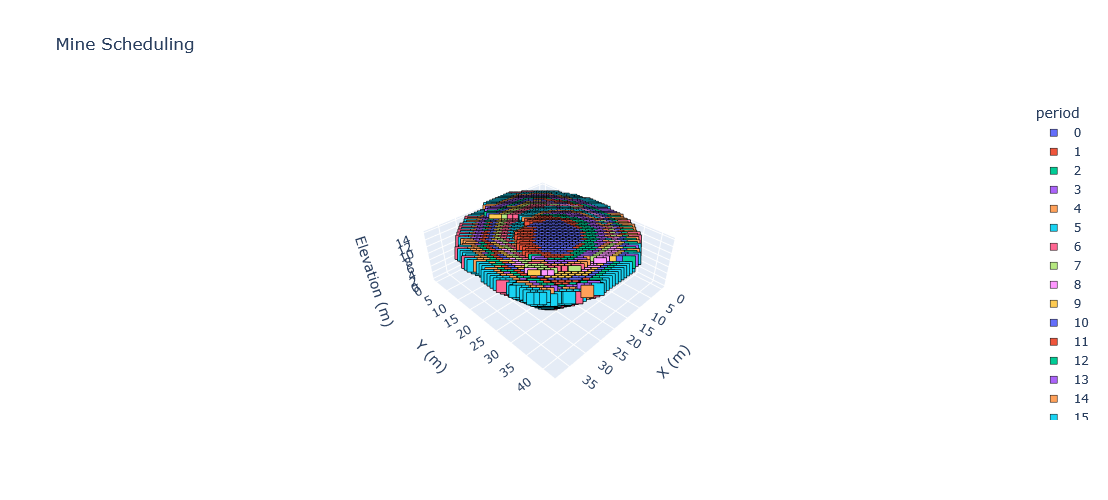

In [8]:
# Block dimensions
dx, dy, dz = 1, 1, 1

# Filter extracted blocks and prepare data
d = blocks.loc[blocks.period.notna()].copy()
d["period"] = d["period"].astype(int)
d[["x","y","z"]] *= [dx, dy, dz]
d["period"] -= d["period"].min()
d["period"] = d["period"].astype(str)

# Axis scaling for correct proportions
r = d[["x","y","z"]].max() - d[["x","y","z"]].min()
s = r.max()

# 3D categorical scatter with Plotly default colors
fig = px.scatter_3d(d, x="x", y="y", z="z", color="period", color_discrete_sequence=px.colors.qualitative.Plotly,
    category_orders={"period": sorted(d["period"], key=int)}, labels={"color": "Periods"}, 
    title="Mine Scheduling", width=900, height=500).update_traces(marker=dict(symbol="square", size=7, 
    line=dict(width=0.5, color="black"))).update_layout(scene=dict(xaxis_title="X (m)", yaxis_title="Y (m)", 
    zaxis_title="Elevation (m)", aspectmode="manual", aspectratio=dict(x=r.x/s, y=r.y/s, z=r.z/s)))
fig.show()

In [9]:
# Salve 3D Plot 
fig.write_html("zuck_small_plot.html", full_html=True, include_plotlyjs="cdn",
    config={"responsive": True}, default_width="100vw", default_height="100vh")

### Capacity & Grade Chart

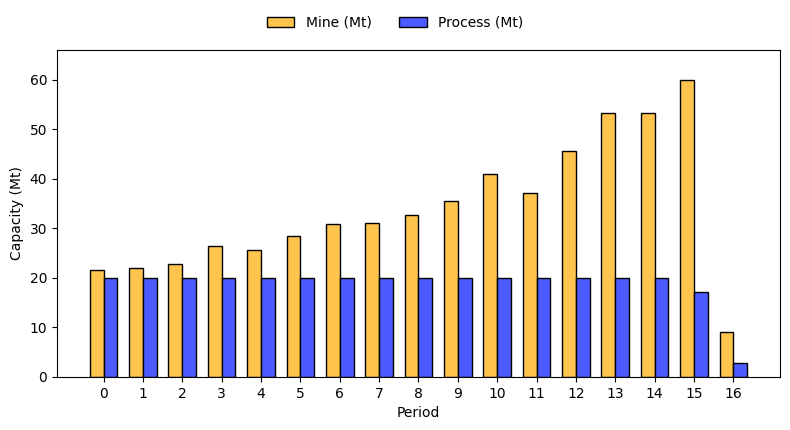

In [10]:
# Consider only extracted blocks
df = blocks.dropna(subset=["period"]).copy()

# Aggregate by period
summary = (df.groupby("period", as_index=False).agg(ton_mine=("rock_tonnes", "sum"), ton_plant=("ore_tonnes", "sum"), ))

# Plot
x = np.arange(len(summary))
w = 0.35
fig, ax1 = plt.subplots(figsize=(8, 4))

# Bars: Mine vs Process capacity (Mt)
ax1.bar(x - w/2, summary["ton_mine"] / 1e6, w, label="Mine (Mt)", color="#FFC44D", edgecolor="black")
ax1.bar(x + w/2, summary["ton_plant"] / 1e6, w, label="Process (Mt)", color="#4C5BFF", edgecolor="black")

ax1.set_xlabel("Period")
ax1.set_ylabel("Capacity (Mt)")
ax1.set_xticks(x)
ax1.set_xticklabels(summary["period"].astype(int))

# Y-axis from zero to slightly above max
ax1.set_ylim(0, 1.1 * max(summary["ton_mine"].max(), summary["ton_plant"].max()) / 1e6)

# Visual hierarchy
ax1.patch.set_visible(False)

# Legend
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08), frameon=False)

plt.tight_layout()
plt.show()

In [11]:
# Salve plot
fig.savefig("zuck_small_results.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# MIP Complete (LP Relaxed Solution)

In [12]:
import time
import pandas as pd
from mip import Model, MAXIMIZE, CONTINUOUS, xsum, OptimizationStatus

# =========================
# Solver
# =========================
try:
    Model(sense=MAXIMIZE, solver_name="GRB").clear()
    solver_name = "GRB"
except Exception:
    solver_name = "CBC"
print(f"Using {solver_name} solver")

# =========================
# Data preparation
# =========================
ids = blocks["id"].tolist()
v = blocks["blockvalue"].tolist()
rock = blocks["rock_tonnes"].tolist()
ore = blocks["ore_tonnes"].tolist()

n_blocks = len(ids)
id_to_idx = {bid: i for i, bid in enumerate(ids)}

# =========================
# Multi-period LP Relaxation
# =========================
code_start = time.time()
model = Model(sense=MAXIMIZE, solver_name=solver_name)
model.max_seconds = 3600
model.verbose = 1
new_log("zuck_small_gurobi_cpit_relaxed.log")  # added: Gurobi log
set_gurobi_log(model, "zuck_small_gurobi_cpit_relaxed.log")  # added: Gurobi log

# Continuous variables (0 <= x <= 1)
x = [[model.add_var(var_type=CONTINUOUS, lb=0.0, ub=1.0, name=f"x_{b}_{t}")
      for t in range(max_period)] for b in range(n_blocks)]

# Objective: maximize NPV
model.objective = xsum(
    (v[b] / ((1 + alpha) ** t)) * x[b][t]
    for b in range(n_blocks)
    for t in range(max_period)
)

# Each block is extracted at most once
for b in range(n_blocks):
    model += xsum(x[b][t] for t in range(max_period)) <= 1

# Precedence (cumulative form)
gen_start = time.time()  # added: time to build the precedence constraints
n_done = 0               # added: progress of the model generation
for bid in ids:
    if bid in precedence:
        b = id_to_idx[bid]
        for prec in precedence[bid]:
            if prec in id_to_idx:
                p = id_to_idx[prec]
                for t in range(max_period):
                    model += (
                        xsum(x[b][tau] for tau in range(t + 1))
                        <= xsum(x[p][tau] for tau in range(t + 1))
                    )
    n_done += 1                                                           # added
    if n_done % max(1, n_blocks // 10) == 0:                              # added
        print(f"  precedences: {100 * n_done / n_blocks:.0f}% of the blocks, {time.time() - gen_start:.0f} s")  # added
print(f"Precedence constraints built in {time.time() - gen_start:.0f} s")  # added

# Maximum capacities per period
for t in range(max_period):
    model += xsum(rock[b] * x[b][t] for b in range(n_blocks)) <= MC
    model += xsum(ore[b] * x[b][t] for b in range(n_blocks)) <= PC

# =========================
# Solve
# =========================
print("Starting multi-period LP relaxation...")
opt_start = time.time()
status = model.optimize()
opt_time = time.time() - opt_start

# =========================
# Results
# =========================
if status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE):
    npv = model.objective_value
    print(f"\nStatus: {status}")
    print(f"NPV: {npv:,.0f}")
    print(f"Optimization time: {opt_time/60:.2f} minutes")

    blocks["period"] = -1
    blocks["x_value"] = 0.0
    total_extracted_frac = 0.0

    for b in range(n_blocks):
        for t in range(max_period):
            val = x[b][t].x
            if val is not None and val > 1e-6:
                blocks.loc[blocks["id"] == ids[b], "period"] = t
                blocks.loc[blocks["id"] == ids[b], "x_value"] = val
                total_extracted_frac += val
                break

    print(f"Total blocks (fractional sum): {total_extracted_frac:.2f}")
    print(f"Total blocks with x > 0.5: {(blocks['x_value'] > 0.5).sum()}")

    print("\nExtraction summary per period:")
    for t in range(max_period):
        frac_proc = sum(ore[b] * (x[b][t].x or 0) for b in range(n_blocks))
        count = sum(1 for b in range(n_blocks) if (x[b][t].x or 0) > 1e-6)
        print(f"  Period {t}: {count:4d} blocks | {frac_proc:10,.0f} t processed")
else:
    print(f"No feasible solution found. Status: {status}")

print(f"\nTotal code time: {(time.time() - code_start)/60:.2f} minutes")

blocks.to_csv("zuck_small_lp_solution.csv", index=False)
print("Solution saved.")

Using GRB solver
  precedences: 10% of the blocks, 3 s
  precedences: 20% of the blocks, 6 s
  precedences: 30% of the blocks, 10 s
  precedences: 40% of the blocks, 16 s
  precedences: 50% of the blocks, 22 s
  precedences: 60% of the blocks, 25 s
  precedences: 70% of the blocks, 34 s
  precedences: 80% of the blocks, 41 s
  precedences: 90% of the blocks, 50 s
  precedences: 100% of the blocks, 60 s
Precedence constraints built in 60 s
Starting multi-period LP relaxation...
No feasible solution found. Status: OptimizationStatus.TRUNCATED

Total code time: 61.59 minutes
Solution saved.


In [13]:
# added: store results
res_lp = store_full("zuck_small_gurobi_cpit_relaxed.log", relax=True)

# MIP Complete, time limit 3,600 s (default MIP gap 1e-4)

In [14]:
import time
import pandas as pd
from mip import Model, MAXIMIZE, BINARY, xsum, OptimizationStatus

# =========================
# Solver
# =========================
try:
    Model(sense=MAXIMIZE, solver_name="GRB").clear()
    solver_name = "GRB"
except Exception:
    solver_name = "CBC"
print(f"Using {solver_name} solver")

# =========================
# Data preparation
# =========================
ids = blocks["id"].tolist()
v = blocks["blockvalue"].tolist()
rock = blocks["rock_tonnes"].tolist()
ore = blocks["ore_tonnes"].tolist()

n_blocks = len(ids)
id_to_idx = {bid: i for i, bid in enumerate(ids)}

# =========================
# Multi-period MIP (integer)
# =========================
code_start = time.time()
model = Model(sense=MAXIMIZE, solver_name=solver_name)
model.max_seconds = 3600          # 1 hour
model.max_mip_gap = 1e-4           # added: relative MIP gap
new_log("zuck_small_gurobi_cpit_gap1e-4.log")  # added: Gurobi log
set_gurobi_log(model, "zuck_small_gurobi_cpit_gap1e-4.log")  # added: Gurobi log
model.verbose = 1

# Binary variables
x = [[model.add_var(var_type=BINARY, name=f"x_{b}_{t}")
      for t in range(max_period)] for b in range(n_blocks)]

# Objective: maximize NPV
model.objective = xsum(
    (v[b] / ((1 + alpha) ** t)) * x[b][t]
    for b in range(n_blocks)
    for t in range(max_period)
)

# 1. Each block is extracted at most once
for b in range(n_blocks):
    model += xsum(x[b][t] for t in range(max_period)) <= 1

# Precedence (cumulative form)
gen_start = time.time()  # added: time to build the precedence constraints
n_done = 0               # added: progress of the model generation
for bid in ids:
    if bid in precedence:
        b = id_to_idx[bid]
        for prec in precedence[bid]:
            if prec in id_to_idx:
                p = id_to_idx[prec]
                for t in range(max_period):
                    model += (
                        xsum(x[b][tau] for tau in range(t + 1))
                        <= xsum(x[p][tau] for tau in range(t + 1))
                    )
    n_done += 1                                                           # added
    if n_done % max(1, n_blocks // 10) == 0:                              # added
        print(f"  precedences: {100 * n_done / n_blocks:.0f}% of the blocks, {time.time() - gen_start:.0f} s")  # added
print(f"Precedence constraints built in {time.time() - gen_start:.0f} s")  # added

# 3. Maximum capacities per period
for t in range(max_period):
    model += xsum(rock[b] * x[b][t] for b in range(n_blocks)) <= MC
    model += xsum(ore[b] * x[b][t] for b in range(n_blocks)) <= PC

# =========================
# Solve
# =========================
print("Starting multi-period MIP optimization...")
opt_start = time.time()
status = model.optimize()
opt_time = time.time() - opt_start

# =========================
# Results
# =========================
if status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE):
    npv = model.objective_value
    print(f"\nStatus: {status}")
    print(f"NPV: {npv:,.0f}")
    print(f"Optimization time: {opt_time/60:.2f} minutes")
    print(f"Gap: {model.gap*100:.4f}%" if model.gap is not None else "")

    # Assign periods to blocks
    blocks["period"] = -1
    extracted = 0

    for b in range(n_blocks):
        for t in range(max_period):
            if x[b][t].x is not None and x[b][t].x > 0.5:
                blocks.loc[blocks["id"] == ids[b], "period"] = t
                extracted += 1
                break

    print(f"Total blocks extracted: {extracted}")

    print("\nExtraction summary per period:")
    for t in range(max_period):
        count = sum(1 for b in range(n_blocks) if x[b][t].x is not None and x[b][t].x > 0.5)
        process_ton = sum(ore[b] for b in range(n_blocks) if x[b][t].x is not None and x[b][t].x > 0.5)
        
        print(f"  Period {t}: {count:4d} blocks | {process_ton:10,.0f} t processed")
else:
    print(f"No feasible solution found. Status: {status}")

print(f"\nTotal code time: {(time.time() - code_start)/60:.2f} minutes")

# Save solution
blocks.to_csv("zuck_small_mip_solution_gap1e-4.csv", index=False)
print("Solution saved to zuck_small_mip_solution_gap1e-4.csv")

Using GRB solver
  precedences: 10% of the blocks, 3 s
  precedences: 20% of the blocks, 6 s
  precedences: 30% of the blocks, 11 s
  precedences: 40% of the blocks, 17 s
  precedences: 50% of the blocks, 23 s
  precedences: 60% of the blocks, 27 s
  precedences: 70% of the blocks, 35 s
  precedences: 80% of the blocks, 43 s
  precedences: 90% of the blocks, 52 s
  precedences: 100% of the blocks, 62 s
Precedence constraints built in 62 s
Starting multi-period MIP optimization...

Status: OptimizationStatus.FEASIBLE
NPV: 35,486,812
Optimization time: 60.37 minutes
Gap: 42400.3138%
Total blocks extracted: 358

Extraction summary per period:
  Period 0:  358 blocks | 12,629,345 t processed
  Period 1:    0 blocks |          0 t processed
  Period 2:    0 blocks |          0 t processed
  Period 3:    0 blocks |          0 t processed
  Period 4:    0 blocks |          0 t processed
  Period 5:    0 blocks |          0 t processed
  Period 6:    0 blocks |          0 t processed
  Period 

In [15]:
# added: store results
res_g4 = store_full("zuck_small_gurobi_cpit_gap1e-4.log", relax=False)

# Comparison: SD-CPIT x CPIT LP (UB) x CPIT integer (time limit 3,600 s)

In [16]:
# added: Comparison SD-CPIT x CPIT LP (UB) x CPIT integer (time limit 3,600 s)
T = max(len(res_lp["discounted"]), len(res_g4["discounted"]), len(res_seq["time"]))
pad = lambda lst, fill: list(lst) + [fill] * (T - len(lst))
ub = res_lp["npv"]

# Discounted value per period (the CPIT models solve all periods at once, so only SD-CPIT has time per period)
per_period = pd.DataFrame({
    "Period": [str(t) for t in range(T)],
    "SD-CPIT": pad(res_seq["discounted"], 0.0),
    "CPIT LP (UB)": pad(res_lp["discounted"], 0.0),
    "CPIT integer (3,600 s)": pad(res_g4["discounted"], 0.0),
    "SD-CPIT Opt Time (s)": pad(res_seq["time"], np.nan),
})
per_period.loc[len(per_period)] = ["NPV", res_seq["npv"], res_lp["npv"], res_g4["npv"], res_seq["opt_time"]]

fmt_val = lambda val: "" if pd.isna(val) else f"{val:,.0f}"
fmt_s = lambda val: "" if pd.isna(val) else f"{val:.2f}"
print("Discounted value per period\n")
print(per_period.to_string(index=False, formatters={**{c: fmt_val for c in per_period.columns[1:4]}, "SD-CPIT Opt Time (s)": fmt_s}))

# Summary
summary = pd.DataFrame({
    "Method": ["SD-CPIT", "CPIT LP (UB)", "CPIT integer (3,600 s)"],
    "NPV": [res_seq["npv"], res_lp["npv"], res_g4["npv"]],
    "Gap to UB (%)": [100 * (ub - r["npv"]) / ub for r in (res_seq, res_lp, res_g4)],
    "Solver bound": [np.nan, res_lp["bound"], res_g4["bound"]],
    "Solver MIP gap (%)": [np.nan, 0.0, 100 * res_g4["mip_gap"]],
    "Opt Time (s)": [res_seq["opt_time"], res_lp["opt_time"], res_g4["opt_time"]],
    "Gurobi log": [res_seq["log"], res_lp["log"], res_g4["log"]],
})
print("\nSummary\n")
print(summary.to_string(index=False, formatters={
    "NPV": fmt_val, "Solver bound": fmt_val, "Gap to UB (%)": lambda val: f"{val:.4f}",
    "Solver MIP gap (%)": lambda val: "" if pd.isna(val) else f"{val:.6f}", "Opt Time (s)": fmt_s}))

# Save comparison
per_period.to_csv("zuck_small_comparison_per_period.csv", index=False)
summary.to_csv("zuck_small_comparison_summary.csv", index=False)

Discounted value per period

Period     SD-CPIT CPIT LP (UB) CPIT integer (3,600 s) SD-CPIT Opt Time (s)
     0  98,287,180          NaN             35,486,812                10.94
     1  92,283,549          NaN                      0                20.54
     2  93,597,307          NaN                      0                12.38
     3  91,358,052          NaN                      0                 4.95
     4  80,397,660          NaN                      0                 5.35
     5  72,748,377          NaN                      0                 9.53
     6  65,716,252          NaN                      0                 6.85
     7  56,029,368          NaN                      0                 4.53
     8  47,356,726          NaN                      0                 3.66
     9  40,325,944          NaN                      0                 1.83
    10  32,788,005          NaN                      0                 2.48
    11  26,748,237          NaN                      0     